# Phase 1 — Retail accessibility in Atlanta (2024)
**ECON 499 | Research progress report**

Question: Are higher-income neighborhoods closer to the two Buckhead shopping malls than to Ponce City Market? This is a cross-sectional association, not an estimate of mall construction effects. The 24 selected ZCTAs are not a random sample. All distance measures are user-collected Google Maps driving miles (collection date not established).

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import pearsonr
BASE = Path.cwd()


## 1. Sources and sample
- ACS 2024 five-year estimates: B19013 median household income, B19083 Gini, B15003 educational attainment (age 25+ bachelor's or higher share, percent), S1701 poverty rate (percent), B25077 median home value. The previously prepared `merged_2024.csv` joins these with the route worksheet `Atlanta_72_Google_Maps_Routes_No_API(1).xlsx`. Income is missing for 30303; keep it for Gini analysis.
- New ACS B01003 population file: 2024 five-year ZCTA total population (not used in the original accessibility regressions).
- `2024_Gaz_zcta_national.txt`: Census internal points, not polygons or population-weighted centroids.
- `mall_area_inputs.csv`: earlier tenant classification of store directories and Jamestown brochure, Simon 2025-12-31 GLA figures supplied earlier. Luxury counts are provisional manual classifications. Ponce 2026 brochure retail/restaurants area is not the same definition as Simon total GLA. These are later snapshots, so weighted indices are exploratory, not measured 2024 attractiveness.

In [2]:
d=pd.read_csv(BASE/'merged_2024.csv',dtype={'ZCTA':str})
a=pd.read_csv(BASE/'mall_area_inputs.csv') if (BASE/'mall_area_inputs.csv').exists() else pd.read_csv(BASE/'Atlanta_GLA_Weighted_Study/mall_area_inputs.csv')
assert not d.duplicated(['ZCTA','Destination']).any()
print('Routes:',len(d),'ZCTAs:',d.ZCTA.nunique())
display(d.groupby('Destination').agg(routes=('ZCTA','size'),income_available=('income','count'),mean_miles=('driving_miles','mean')).round(2))
display(a[['Mall','RetailCount','StrictLuxuryCount','StrictLuxuryRatio','Area_sqft','Area_source']])


Routes: 72 ZCTAs: 24


,routes,income_available,mean_miles
Destination,,,
Lenox Square,24,23,7.38
Phipps Plaza,24,23,7.93
Ponce City Market,24,23,5.41


,Mall,RetailCount,StrictLuxuryCount,StrictLuxuryRatio,Area_sqft,Area_source
0,Lenox Square,135,15,0.1111,1546028,Simon 2025-12-31 Total GLA
1,Phipps Plaza,67,30,0.4478,1127024,Simon 2025-12-31 Total GLA
2,Ponce City Market,39,0,0.0000,327000,Jamestown 2026 brochure p.7 Retail & Restauran...


## 2. Finding: income and driving distance
Method: Pearson correlation on available observations, separately for each destination. P-values are nominal, two-sided and exploratory. The scatterplots use ACS income in dollars; the fitted line is descriptive.

,Mall,Outcome,N,Pearson_r,p
0,Lenox Square,income,23,-0.5274,0.0097
1,Lenox Square,gini,24,0.2069,0.3321
2,Phipps Plaza,income,23,-0.5367,0.0083
3,Phipps Plaza,gini,24,0.1388,0.5177
4,Ponce City Market,income,23,0.0630,0.7752
5,Ponce City Market,gini,24,0.0922,0.6682


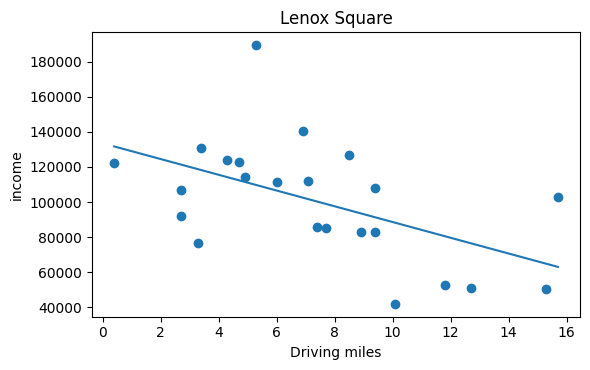

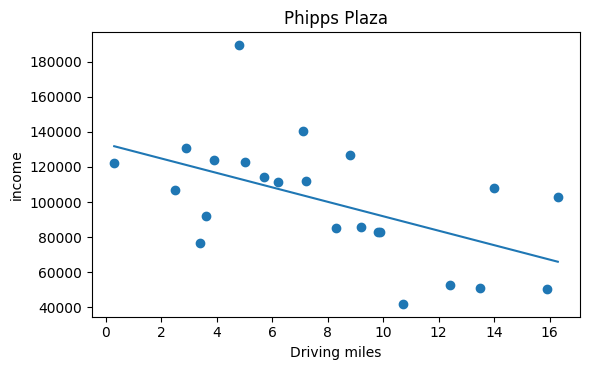

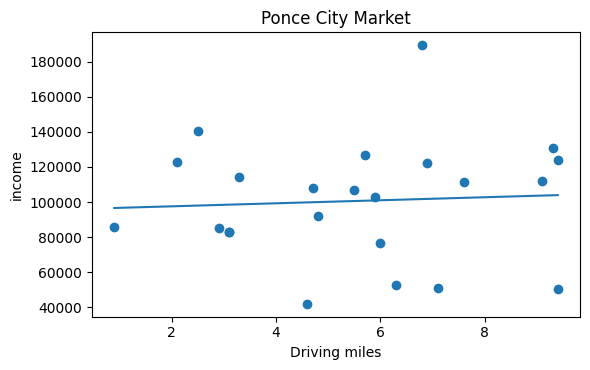

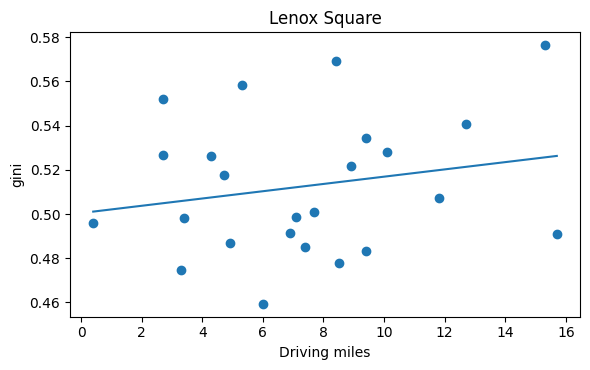

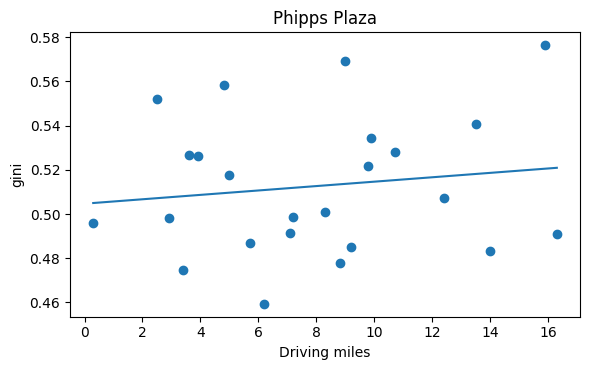

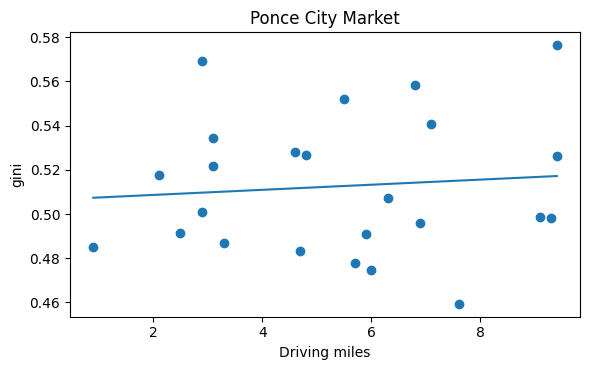

In [3]:
out=[]
for mall,g in d.groupby('Destination'):
    for y in ['income','gini']:
        t=g.dropna(subset=[y,'driving_miles']); r,p=pearsonr(t.driving_miles,t[y]);out.append([mall,y,len(t),r,p])
corr=pd.DataFrame(out,columns=['Mall','Outcome','N','Pearson_r','p']);display(corr.round(4))
for y in ['income','gini']:
    for mall,g in d.groupby('Destination'):
        t=g.dropna(subset=[y]); x=t.driving_miles; v=t[y]; plt.figure(figsize=(6,3.8));plt.scatter(x,v);xx=np.linspace(x.min(),x.max());plt.plot(xx,np.polyval(np.polyfit(x,v,1),xx));plt.xlabel('Driving miles');plt.ylabel(y);plt.title(mall);plt.tight_layout();plt.show()


**Interpretation:** Negative income-distance associations for Buckhead malls are consistent with wealthier neighborhoods being closer. Ponce shows a weaker pattern. Gini is inequality, not income level; a weak relationship does not prove absence of an effect.

## 3. Finding: income quartiles
Rank the 23 nonmissing income ZCTAs into four groups using pandas qcut. Compare mean route miles. A two-sided permutation test compares the highest and lowest groups, holding group sizes fixed; spatial dependence may invalidate exchangeability. No causal interpretation.

,Lenox Square,Phipps Plaza,Ponce City Market,income
quartile,,,,
Q1,10.43,10.97,6.08,59325.83
Q2,7.52,8.28,3.85,92614.83
Q3,5.56,6.68,6.32,113536.20
Q4,5.52,5.42,5.97,139098.83


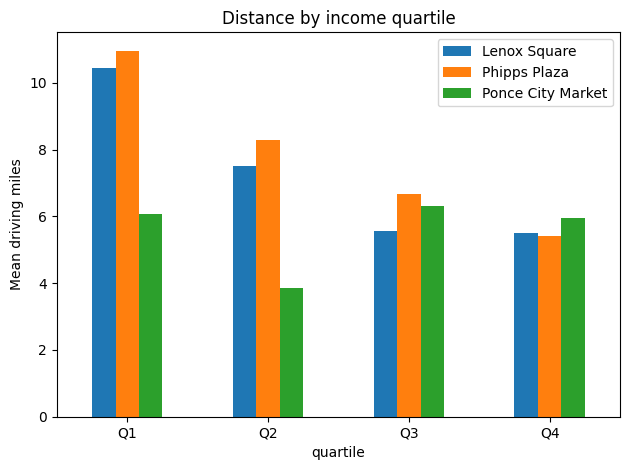

In [4]:
w=d.pivot(index='ZCTA',columns='Destination',values='driving_miles').join(d.drop_duplicates('ZCTA').set_index('ZCTA')[['income','gini','education_share','home_value','poverty_rate']]);v=w.dropna(subset=['income']).copy();v['quartile']=pd.qcut(v.income,4,labels=['Q1','Q2','Q3','Q4']); malls=a.Mall.tolist()
q=v.groupby('quartile',observed=True)[malls+['income']].mean();display(q.round(2));q[malls].plot.bar(rot=0);plt.ylabel('Mean driving miles');plt.title('Distance by income quartile');plt.tight_layout();plt.show()


## 4. Finding: gravity accessibility indices
For each origin, calculate sum of A/(1 + miles)^lambda, lambda=1 or 2. Equal weights use A=1; GLA and GLA × (1 + luxury ratio) normalize by mean A across malls. Luxury-only weights use area in millions × strict luxury ratio; luxury-count weights use strict tenant counts. These are potential access measures, not observed choice probabilities.

,Metric,Q4 minus Q1,Permutation p
0,Lenox Square,-4.9167,0.0297
1,Phipps Plaza,-5.5500,0.0210
2,Ponce City Market,-0.1167,0.9395
3,LuxuryOnly_lambda1,0.0452,0.0776
4,GLA_StrictLuxury_lambda1,0.1816,0.0633


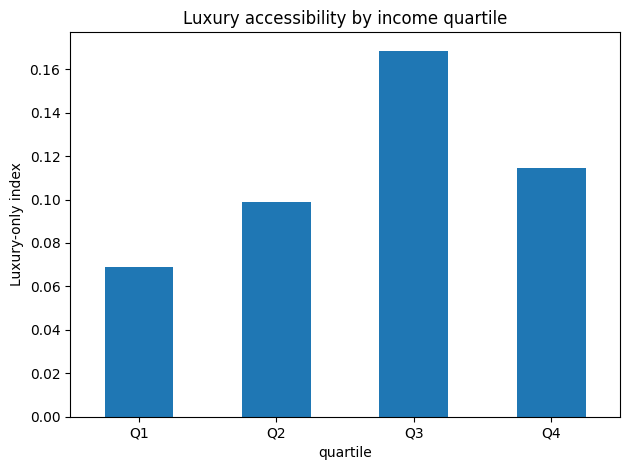

In [5]:
for lam in [1,2]:
    for name,weights in {'Equal':np.ones(len(a)),'GLA':a.Area_sqft,'GLA_StrictLuxury':a.Area_sqft*(1+a.StrictLuxuryRatio),'GLA_BroadLuxury':a.Area_sqft*(1+a.BroadLuxuryRatio),'LuxuryOnly':a.Area_sqft/1e6*a.StrictLuxuryRatio,'LuxuryCount':a.StrictLuxuryCount}.items():
        weights=np.asarray(weights);weights=weights/weights.mean() if name in ['GLA','GLA_StrictLuxury','GLA_BroadLuxury'] else weights
        w[f'{name}_lambda{lam}']=sum(weight/(1+w[mall])**lam for mall,weight in zip(malls,weights))
v=w.dropna(subset=['income']).copy();v['quartile']=pd.qcut(v.income,4,labels=['Q1','Q2','Q3','Q4']); v['log_income']=np.log(v.income)
rng=np.random.default_rng(20261120);tests=[]
for x in malls+['LuxuryOnly_lambda1','GLA_StrictLuxury_lambda1']:
    lo=v.loc[v.quartile=='Q1',x].to_numpy(); hi=v.loc[v.quartile=='Q4',x].to_numpy(); obs=hi.mean()-lo.mean(); z=np.r_[hi,lo]; sims=[rng.permutation(z) for _ in range(20000)]; p=(1+sum(abs(s[:len(hi)].mean()-s[len(hi):].mean())>=abs(obs) for s in sims))/20001;tests.append([x,obs,p])
display(pd.DataFrame(tests,columns=['Metric','Q4 minus Q1','Permutation p']).round(4))
v.groupby('quartile',observed=True).LuxuryOnly_lambda1.mean().plot.bar(rot=0);plt.ylabel('Luxury-only index');plt.title('Luxury accessibility by income quartile');plt.tight_layout();plt.show()


## 5. Finding: controls and robustness
OLS with HC3 standard errors, outcome log income or Gini. Compare unadjusted models, education-only controls, and full controls (education, poverty, home value). These controls are strongly related to income and may themselves reflect residential sorting; coefficients are conditional correlations, not causal estimates. Income sample 23, Gini sample 24. Multiple specifications are exploratory.

,Outcome,Metric,Spec,N,Beta,p,Low,High,Adj_R2
0,income,Lenox Square,Unadjusted,23,-0.0532,0.0143,-0.0957,-0.0106,0.2970
1,income,Lenox Square,Education,23,0.0213,0.0314,0.0019,0.0408,0.8377
2,income,Lenox Square,Full,23,0.0174,0.0248,0.0022,0.0327,0.9348
3,income,Phipps Plaza,Unadjusted,23,-0.0472,0.0105,-0.0833,-0.0111,0.2867
4,income,Phipps Plaza,Education,23,0.0159,0.1359,-0.0050,0.0369,0.8308
5,income,Phipps Plaza,Full,23,0.0128,0.1293,-0.0037,0.0293,0.9291
6,income,Ponce City Market,Unadjusted,23,0.0008,0.9812,-0.0622,0.0637,-0.0476
7,income,Ponce City Market,Education,23,0.0311,0.0095,0.0076,0.0546,0.8572
8,income,Ponce City Market,Full,23,0.0011,0.9028,-0.0164,0.0185,0.9157
9,income,Equal_lambda1,Unadjusted,23,0.4416,0.4327,-0.6617,1.5450,0.0706


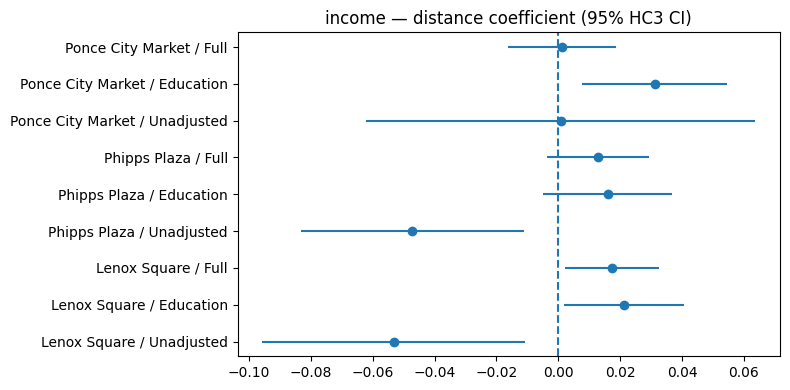

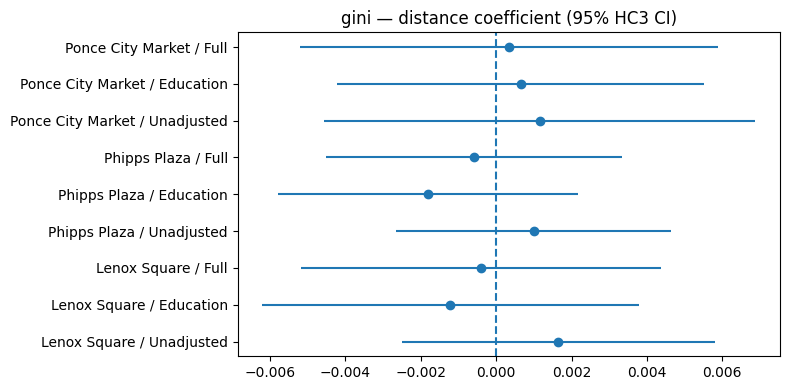

In [6]:
rows=[]
for y in ['income','gini']:
    t=w.copy(); t['outcome']=np.log(t.income) if y=='income' else t.gini
    for x in malls+['Equal_lambda1','LuxuryOnly_lambda1','LuxuryOnly_lambda2','LuxuryCount_lambda1','GLA_StrictLuxury_lambda1','GLA_lambda1','GLA_BroadLuxury_lambda1']:
        for spec,ctrl in [('Unadjusted',[]),('Education',['education_share']),('Full',['education_share','poverty_rate','home_value'])]:
            z=t[['outcome',x]+ctrl].dropna();fit=sm.OLS(z.outcome,sm.add_constant(z[[x]+ctrl])).fit(cov_type='HC3');ci=fit.conf_int().loc[x];rows.append([y,x,spec,len(z),fit.params[x],fit.pvalues[x],ci.iloc[0],ci.iloc[1],fit.rsquared_adj])
reg=pd.DataFrame(rows,columns=['Outcome','Metric','Spec','N','Beta','p','Low','High','Adj_R2']);display(reg.round(4))
for y in ['income','gini']:
    z=reg[(reg.Outcome==y)&reg.Metric.isin(malls)].reset_index(drop=True);plt.figure(figsize=(8,4));plt.errorbar(z.Beta,range(len(z)),xerr=[z.Beta-z.Low,z.High-z.Beta],fmt='o');plt.yticks(range(len(z)),z.Metric+' / '+z.Spec);plt.axvline(0,linestyle='--');plt.title(y+' — distance coefficient (95% HC3 CI)');plt.tight_layout();plt.show()


**Interpretation:** The negative unadjusted Buckhead relationship is not stable after controls. Lenox's log-income distance coefficient reverses sign and remains nominally significant; do not describe all controlled results as insignificant. The gravity indices do not provide robust evidence of an income association after controls. The sample is small, and spatial clustering/multiple comparisons limit inference.

## 6. Geographic context
Census Gazetteer internal points only. No ZIP boundary map is claimed.

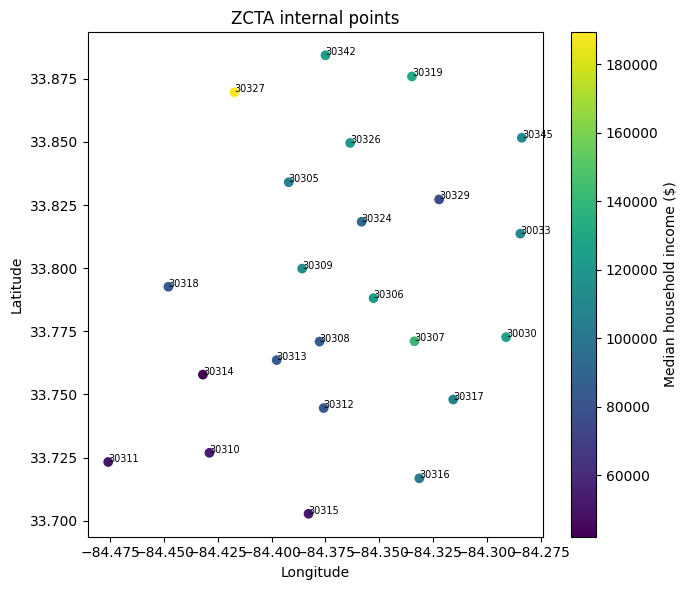

In [7]:
geo=pd.read_csv(BASE/'2024_Gaz_zcta_national.txt',sep='\t',dtype={'GEOID':str});geo.columns=geo.columns.str.strip();g=w.reset_index().merge(geo[['GEOID','INTPTLAT','INTPTLONG']],left_on='ZCTA',right_on='GEOID');g=g.dropna(subset=['income']);plt.figure(figsize=(7,6));s=plt.scatter(g.INTPTLONG,g.INTPTLAT,c=g.income);plt.colorbar(s,label='Median household income ($)');
for r in g.itertuples(): plt.annotate(r.ZCTA,(r.INTPTLONG,r.INTPTLAT),fontsize=7)
plt.xlabel('Longitude');plt.ylabel('Latitude');plt.title('ZCTA internal points');plt.tight_layout();plt.show()


## 7. Conclusion
Phase 1 documents spatial accessibility rather than actual shopping choices. Higher-income ZCTAs are closer to Buckhead in simple comparisons, but controls alter the relationship. Phase 2 supplies reported device flows; Phase 3 must align the geographic vintages before relating flows to socioeconomic data.